# 🏠 House Prices — Preprocesamiento Final del Pipeline

> **Kaggle Competition** | Chalito · LYONSOFT PERU
> Este notebook toma los artefactos del Feature Engineering y construye
> los datasets finales listos para entrenar modelos.

---
### Posición en el pipeline
```
📓 01_EDA.ipynb                  ✅ completado
📓 02_FeatureEngineering.ipynb   ✅ completado  → produce X_train_FE.parquet / X_test_FE.parquet
📓 03_Preprocessing.ipynb        ◀ ESTE NOTEBOOK
📓 04_Models.ipynb               pendiente
```

### ¿Qué hace este notebook?
El FE ya encodificó y limpió todo. Aquí:
1. Cargamos los parquets del FE
2. Validamos integridad (shapes, nulos, dtypes)
3. Aplicamos transformación log1p al target y a features sesgadas
4. Construimos dos versiones del dataset:
   - **Versión A** (escalada) → para modelos lineales: Ridge, Lasso, ElasticNet, SVR
   - **Versión B** (sin escalar) → para tree-based: XGBoost, LightGBM, RandomForest
5. Selección de features con Lasso (eliminamos ruido)
6. Validación con baseline 10-fold CV
7. Guardado de artefactos finales

In [1]:
# ─── 0. IMPORTACIONES ───────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import skew
import joblib, os

from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import mean_squared_error

plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.grid': True, 'grid.alpha': 0.35,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 12,
})

COLOR_MAIN    = '#2563EB'
COLOR_ACCENT  = '#F59E0B'
COLOR_DANGER  = '#EF4444'
COLOR_SUCCESS = '#10B981'
COLOR_PURPLE  = '#7C3AED'

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', '{:.4f}'.format)

print('✅ Librerías cargadas')
print(f'   sklearn  {__import__("sklearn").__version__}')
print(f'   pandas   {pd.__version__}')
print(f'   numpy    {np.__version__}')

✅ Librerías cargadas
   sklearn  1.9.0
   pandas   3.0.3
   numpy    2.4.6


---
## 1 · Carga de artefactos del Feature Engineering
> Consumimos directamente los `.parquet` que produjo el notebook anterior.

In [4]:
# ─── 1.1 CARGAR PARQUETS DEL FE ────────────────────────────────────────────
X_train = pd.read_parquet('X_train_FE.parquet')
X_test  = pd.read_parquet('X_test_FE.parquet')
y_raw   = np.load('y_train.npy')          # ya en log-space desde el notebook FE
y       = pd.Series(y_raw, name='SalePrice_log')

# IDs del test para el submission final
test_ids = pd.read_csv('../data/test.csv')['Id']

print('─' * 55)
print(f'  X_train : {X_train.shape}')
print(f'  X_test  : {X_test.shape}')
print(f'  y       : {y.shape}  (ya en log1p-space)')
print(f'  test_ids: {test_ids.shape}')
print('─' * 55)
print(f'\n  Target → media={y.mean():.4f}  std={y.std():.4f}  skew={y.skew():.4f}')

───────────────────────────────────────────────────────
  X_train : (1456, 288)
  X_test  : (1459, 288)
  y       : (1456,)  (ya en log1p-space)
  test_ids: (1459,)
───────────────────────────────────────────────────────

  Target → media=12.0219  std=0.3961  skew=0.0655


---
## 2 · Validación de integridad
> Verificamos que no haya nulos, shapes incorrectos ni columnas problemáticas.

In [5]:
# ─── 2.1 CHECKS DE INTEGRIDAD ───────────────────────────────────────────────
issues = []

# Nulos
n_null_train = X_train.isnull().sum().sum()
n_null_test  = X_test.isnull().sum().sum()
if n_null_train > 0: issues.append(f'X_train tiene {n_null_train} nulos')
if n_null_test  > 0: issues.append(f'X_test tiene {n_null_test} nulos')

# Columnas distintas
only_train = set(X_train.columns) - set(X_test.columns)
only_test  = set(X_test.columns)  - set(X_train.columns)
if only_train: issues.append(f'Cols solo en train: {only_train}')
if only_test:  issues.append(f'Cols solo en test:  {only_test}')

# Shapes coherentes
if len(y) != len(X_train): issues.append('len(y) != len(X_train)')

# Infinitos
n_inf_train = np.isinf(X_train.select_dtypes(np.number)).sum().sum()
n_inf_test  = np.isinf(X_test.select_dtypes(np.number)).sum().sum()
if n_inf_train > 0: issues.append(f'X_train tiene {n_inf_train} valores infinitos')
if n_inf_test  > 0: issues.append(f'X_test  tiene {n_inf_test} valores infinitos')

if issues:
    print('⚠️  PROBLEMAS DETECTADOS:')
    for issue in issues:
        print(f'   ❌ {issue}')
    # Corrección automática de nulos residuales
    X_train = X_train.fillna(0)
    X_test  = X_test.fillna(0)
    X_train.replace([np.inf, -np.inf], 0, inplace=True)
    X_test.replace([np.inf, -np.inf],  0, inplace=True)
    print('\n   → Nulos e infinitos corregidos con 0')
else:
    print('✅ Validación completa — sin problemas detectados')

print(f'\n  Nulos train: {X_train.isnull().sum().sum()}')
print(f'  Nulos test:  {X_test.isnull().sum().sum()}')
print(f'  Infinitos train: {np.isinf(X_train.select_dtypes(np.number)).sum().sum()}')
print(f'  Infinitos test:  {np.isinf(X_test.select_dtypes(np.number)).sum().sum()}')

✅ Validación completa — sin problemas detectados

  Nulos train: 0
  Nulos test:  0
  Infinitos train: 0
  Infinitos test:  0


In [6]:
# ─── 2.2 ANÁLISIS DE TIPOS DE COLUMNAS ──────────────────────────────────────
dtype_summary = X_train.dtypes.value_counts()
print('Distribución de dtypes en X_train:')
print(dtype_summary.to_string())

# Columnas no numéricas (no deberían existir en este punto)
non_numeric = X_train.select_dtypes(exclude=[np.number]).columns.tolist()
if non_numeric:
    print(f'\n⚠️  Columnas no numéricas encontradas: {non_numeric}')
    # Intentar convertir o eliminar
    for col in non_numeric:
        try:
            X_train[col] = pd.to_numeric(X_train[col], errors='coerce').fillna(0)
            X_test[col]  = pd.to_numeric(X_test[col],  errors='coerce').fillna(0)
            print(f'   ✅ {col} convertida a numérica')
        except Exception:
            X_train.drop(columns=[col], inplace=True)
            X_test.drop(columns=[col],  inplace=True)
            print(f'   🗑️  {col} eliminada')
else:
    print('\n✅ Todas las columnas son numéricas')

print(f'\nShape final: X_train={X_train.shape} | X_test={X_test.shape}')

Distribución de dtypes en X_train:
int64      243
float64     45

✅ Todas las columnas son numéricas

Shape final: X_train=(1456, 288) | X_test=(1459, 288)


---
## 3 · Tratamiento de skewness en features numéricas
> Reducir el sesgo de las variables de entrada mejora los modelos lineales.
> Los modelos tree-based no lo necesitan, pero no les hace daño.

In [7]:
# ─── 3.1 DETECTAR Y CORREGIR SKEWNESS ──────────────────────────────────────
# Excluir columnas binarias (0/1) y columnas que ya fueron log-transformadas en FE
binary_cols  = [c for c in X_train.columns if X_train[c].nunique() <= 2]
log_cols     = [c for c in X_train.columns if c.startswith('log_')]
skip_cols    = set(binary_cols + log_cols)

# Candidatas: numéricas continuas con valores >= 0
candidates = [
    c for c in X_train.select_dtypes(include=[np.number]).columns
    if c not in skip_cols and X_train[c].min() >= 0 and X_train[c].max() > 1
]

skew_before = pd.Series({c: skew(X_train[c].dropna()) for c in candidates})
high_skew   = skew_before[skew_before.abs() > 0.75].sort_values(ascending=False)

print(f'Features candidatas a corrección: {len(candidates)}')
print(f'Features con |skew| > 0.75:       {len(high_skew)}')
print(f'\nTop 15 más sesgadas:')
print(high_skew.head(15).to_string())

Features candidatas a corrección: 88
Features con |skew| > 0.75:       49

Top 15 más sesgadas:
MiscVal              24.4182
PoolArea             17.5046
LotArea              12.5746
3SsnPorch            10.2793
LowQualFinSF          8.9893
LandSlope             4.8013
KitchenAbvGr          4.4767
BsmtFinSF2            4.2442
BsmtHalfBath          4.1247
ScreenPorch           4.1114
BsmtFinType2          3.2879
EnclosedPorch         3.0813
SaleType_TargetEnc    2.8190
MasVnrArea            2.6548
OpenPorchSF           2.3374


In [8]:
# ─── 3.2 APLICAR LOG1P (solo a las que no vienen del FE ya transformadas) ───
# Verificar cuáles ya fueron transformadas en el notebook de FE
already_log = log_cols  # columnas que empiezan con 'log_'
to_transform = [c for c in high_skew.index if c not in skip_cols]

for col in to_transform:
    # Aplicar log1p en train y test simultáneamente
    X_train[col] = np.log1p(X_train[col].clip(lower=0))
    X_test[col]  = np.log1p(X_test[col].clip(lower=0))

# Verificar mejora
skew_after = pd.Series({c: skew(X_train[c].dropna()) for c in to_transform})
comparison = pd.DataFrame({
    'Skew_antes':  high_skew[to_transform],
    'Skew_despues': skew_after,
}).round(4)
comparison['Reduccion_%'] = (
    (comparison['Skew_antes'].abs() - comparison['Skew_despues'].abs())
    / comparison['Skew_antes'].abs() * 100
).round(1)

print(f'✅ log1p aplicado a {len(to_transform)} features')
print(f'\nComparativa skewness (top 15):')
display(comparison.head(15).style
        .background_gradient(cmap='RdYlGn', subset=['Reduccion_%'])
        .format({'Skew_antes':'{:.3f}','Skew_despues':'{:.3f}','Reduccion_%':'{:.1f}%'}))

✅ log1p aplicado a 49 features

Comparativa skewness (top 15):


,Skew_antes,Skew_despues,Reduccion_%
MiscVal,24.418,5.157,78.9%
PoolArea,17.505,16.989,2.9%
LotArea,12.575,-0.180,98.6%
3SsnPorch,10.279,7.716,24.9%
LowQualFinSF,8.989,7.442,17.2%
LandSlope,4.801,4.423,7.9%
KitchenAbvGr,4.477,3.859,13.8%
BsmtFinSF2,4.244,2.516,40.7%
BsmtHalfBath,4.125,3.952,4.2%
ScreenPorch,4.111,3.142,23.6%


---
## 4 · Construcción de las dos versiones del dataset
> Los modelos lineales necesitan **scaling**.
> Los modelos tree-based funcionan mejor **sin scaling** (mantienen interpretabilidad).

```
VERSION A (escalada)   → Ridge, Lasso, ElasticNet, SVR
VERSION B (sin escalar)→ XGBoost, LightGBM, RandomForest, CatBoost
```

In [9]:
# ─── 4.1 VERSIÓN A — RobustScaler (para modelos lineales) ──────────────────
# RobustScaler usa mediana e IQR → robusto ante outliers residuales
# Mejor que StandardScaler para datos con colas largas como precios de casas

scaler_robust = RobustScaler()
X_train_scaled = scaler_robust.fit_transform(X_train)   # fit SOLO en train
X_test_scaled  = scaler_robust.transform(X_test)        # transform en test

print('✅ Versión A — RobustScaler')
print(f'   X_train_scaled : {X_train_scaled.shape}')
print(f'   X_test_scaled  : {X_test_scaled.shape}')
print(f'   Media post-scale (deber ser ~0): {X_train_scaled.mean():.4f}')
print(f'   Std  post-scale (deber ser ~1):  {X_train_scaled.std():.4f}')

# Guardar scaler
joblib.dump(scaler_robust, 'scaler_robust.pkl')
print('   scaler_robust.pkl guardado')

✅ Versión A — RobustScaler
   X_train_scaled : (1456, 288)
   X_test_scaled  : (1459, 288)
   Media post-scale (deber ser ~0): -0.0353
   Std  post-scale (deber ser ~1):  5.0005
   scaler_robust.pkl guardado


In [10]:
# ─── 4.2 VERSIÓN B — Sin scaling (para tree-based) ──────────────────────────
# XGBoost y LightGBM no requieren scaling
# Mantener como numpy arrays para compatibilidad con ambos frameworks

X_train_raw = X_train.values.astype(np.float32)
X_test_raw  = X_test.values.astype(np.float32)

print('✅ Versión B — Sin scaling (tree-based)')
print(f'   X_train_raw : {X_train_raw.shape}  dtype={X_train_raw.dtype}')
print(f'   X_test_raw  : {X_test_raw.shape}   dtype={X_test_raw.dtype}')
print(f'   Min: {X_train_raw.min():.4f} | Max: {X_train_raw.max():.4f} | Mean: {X_train_raw.mean():.4f}')

✅ Versión B — Sin scaling (tree-based)
   X_train_raw : (1456, 288)  dtype=float32
   X_test_raw  : (1459, 288)   dtype=float32
   Min: 0.0000 | Max: 12804576.0000 | Mean: 31064.8887


---
## 5 · Selección de features con Lasso
> Lasso pone a cero los coeficientes de features redundantes o con ruido.
> Usamos esto para construir un dataset reducido más limpio.

In [11]:
# ─── 5.1 LASSO COMO SELECTOR DE FEATURES ────────────────────────────────────
lasso_selector = Lasso(alpha=0.0003, max_iter=15000, random_state=42)
lasso_selector.fit(X_train_scaled, y)

coef_mask    = lasso_selector.coef_ != 0
n_selected   = coef_mask.sum()
n_eliminated = (~coef_mask).sum()

print(f'Lasso feature selection (α=0.0003):')
print(f'  Features retenidas  (coef ≠ 0): {n_selected}')
print(f'  Features eliminadas (coef = 0): {n_eliminated}')
print(f'  Reducción: {n_eliminated / X_train.shape[1] * 100:.1f}% de features eliminadas')

# Dataset reducido
X_train_lasso = X_train_scaled[:, coef_mask]
X_test_lasso  = X_test_scaled[:, coef_mask]
feature_names_lasso = X_train.columns[coef_mask].tolist()

print(f'\n  X_train_lasso: {X_train_lasso.shape}')
print(f'  X_test_lasso:  {X_test_lasso.shape}')

Lasso feature selection (α=0.0003):
  Features retenidas  (coef ≠ 0): 126
  Features eliminadas (coef = 0): 162
  Reducción: 56.2% de features eliminadas

  X_train_lasso: (1456, 126)
  X_test_lasso:  (1459, 126)


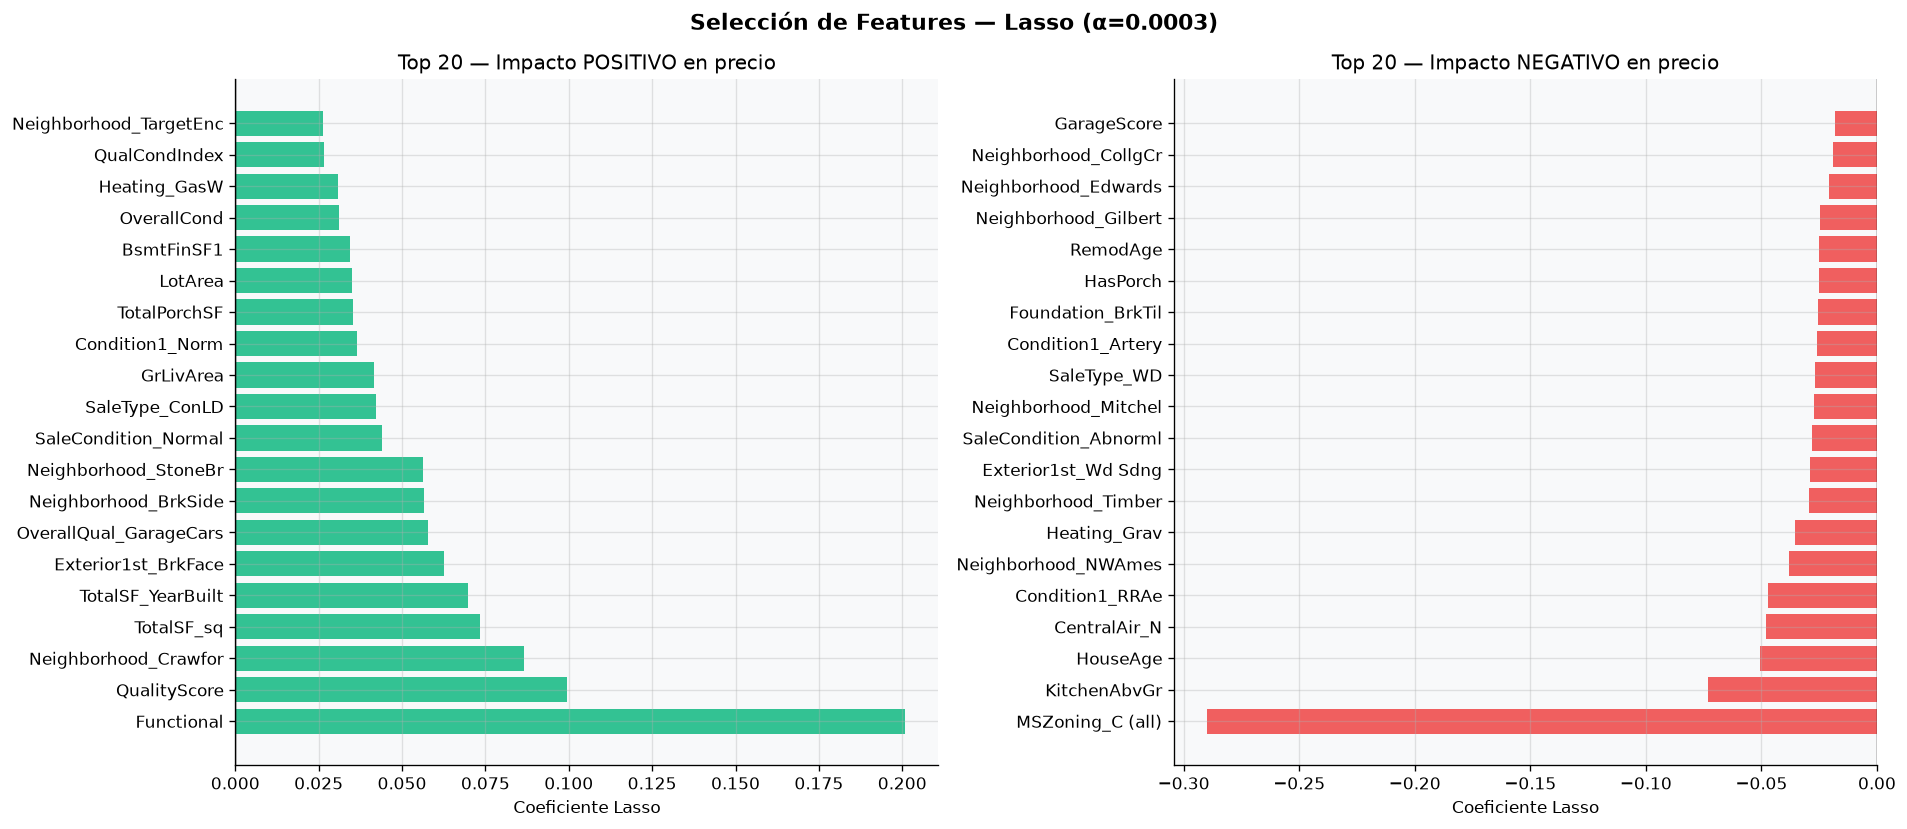


🏆 Top 15 features por importancia absoluta Lasso:
   ▼ MSZoning_C (all)                    coef = -0.28976
   ▲ Functional                          coef = +0.20080
   ▲ QualityScore                        coef = +0.09934
   ▲ Neighborhood_Crawfor                coef = +0.08657
   ▲ TotalSF_sq                          coef = +0.07352
   ▼ KitchenAbvGr                        coef = -0.07317
   ▲ TotalSF_YearBuilt                   coef = +0.06992
   ▲ Exterior1st_BrkFace                 coef = +0.06251
   ▲ OverallQual_GarageCars              coef = +0.05787
   ▲ Neighborhood_BrkSide                coef = +0.05664
   ▲ Neighborhood_StoneBr                coef = +0.05618
   ▼ HouseAge                            coef = -0.05049
   ▼ CentralAir_N                        coef = -0.04785
   ▼ Condition1_RRAe                     coef = -0.04717
   ▲ SaleCondition_Normal                coef = +0.04386


In [12]:
# ─── 5.2 VISUALIZAR IMPORTANCIA LASSO ───────────────────────────────────────
coef_df = pd.DataFrame({
    'Feature': X_train.columns[coef_mask],
    'Coef_Abs': np.abs(lasso_selector.coef_[coef_mask]),
    'Coef':     lasso_selector.coef_[coef_mask]
}).sort_values('Coef_Abs', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Selección de Features — Lasso (α=0.0003)', fontweight='bold', fontsize=13)

# Top 20 positivos
ax = axes[0]
top20_pos = coef_df.nlargest(20, 'Coef')
bars = ax.barh(top20_pos['Feature'], top20_pos['Coef'], color=COLOR_SUCCESS, alpha=0.85)
ax.set_xlabel('Coeficiente Lasso')
ax.set_title('Top 20 — Impacto POSITIVO en precio')
ax.axvline(0, color='black', linewidth=0.8)

# Top 20 negativos
ax = axes[1]
top20_neg = coef_df.nsmallest(20, 'Coef')
bars2 = ax.barh(top20_neg['Feature'], top20_neg['Coef'], color=COLOR_DANGER, alpha=0.85)
ax.set_xlabel('Coeficiente Lasso')
ax.set_title('Top 20 — Impacto NEGATIVO en precio')
ax.axvline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.savefig('prep_01_lasso_importance.png', bbox_inches='tight', dpi=120)
plt.show()

print('\n🏆 Top 15 features por importancia absoluta Lasso:')
for _, row in coef_df.head(15).iterrows():
    sign = '▲' if row['Coef'] > 0 else '▼'
    print(f'   {sign} {row["Feature"]:<35} coef = {row["Coef"]:+.5f}')

---
## 6 · Validación con baseline 10-fold CV
> Evaluamos las 3 versiones del dataset con modelos lineales simples.
> Esto confirma que el preprocesamiento es correcto antes de pasar a modelos avanzados.

In [13]:
# ─── 6.1 FUNCIÓN RMSLE CV ───────────────────────────────────────────────────
def rmsle_cv(model, X, y, n_folds=10, label=''):
    """RMSLE con K-Fold CV. y ya está en log-space → RMSE ≡ RMSLE."""
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
    scores = np.sqrt(-cross_val_score(
        model, X, y,
        scoring='neg_mean_squared_error', cv=kf, n_jobs=-1
    ))
    print(f'  {label:<40} RMSLE = {scores.mean():.5f} ± {scores.std():.5f}')
    return scores

print('Evaluando versiones del dataset (10-fold CV)...')
print('─' * 65)
print('RIDGE α=10')
s_full   = rmsle_cv(Ridge(alpha=10), X_train_scaled, y, label='Versión A (full, escalada)')
s_lasso  = rmsle_cv(Ridge(alpha=10), X_train_lasso,  y, label='Versión A reducida (Lasso sel.)')
s_raw    = rmsle_cv(Ridge(alpha=10), X_train_raw,    y, label='Versión B (sin scaling)')
print('\nLASSO α=0.0003')
s_l_full = rmsle_cv(Lasso(alpha=0.0003, max_iter=15000), X_train_scaled, y, label='Lasso full escalada')
s_l_red  = rmsle_cv(Lasso(alpha=0.0003, max_iter=15000), X_train_lasso,  y, label='Lasso reducida')
print('\nELASTICNET α=0.0005 l1=0.9')
s_e_full = rmsle_cv(ElasticNet(alpha=0.0005, l1_ratio=0.9, max_iter=15000),
                    X_train_scaled, y, label='ElasticNet full escalada')
print('─' * 65)

Evaluando versiones del dataset (10-fold CV)...
─────────────────────────────────────────────────────────────────
RIDGE α=10
  Versión A (full, escalada)               RMSLE = 0.11010 ± 0.01300
  Versión A reducida (Lasso sel.)          RMSLE = 0.10674 ± 0.01205
  Versión B (sin scaling)                  RMSLE = 0.10956 ± 0.01288

LASSO α=0.0003
  Lasso full escalada                      RMSLE = 0.10926 ± 0.01259
  Lasso reducida                           RMSLE = 0.10799 ± 0.01192

ELASTICNET α=0.0005 l1=0.9
  ElasticNet full escalada                 RMSLE = 0.10964 ± 0.01286
─────────────────────────────────────────────────────────────────



📊 RANKING DE CONFIGURACIONES (menor RMSLE = mejor):


,Configuración,RMSLE_Mean,RMSLE_Std
0,Ridge — reducida (Lasso),0.10674,0.01205
1,Lasso — reducida,0.10799,0.01192
2,Lasso — full escalada,0.10926,0.01259
3,Ridge — sin scaling,0.10956,0.01288
4,ElasticNet — full escalada,0.10964,0.01286
5,Ridge — full escalada,0.11010,0.01300


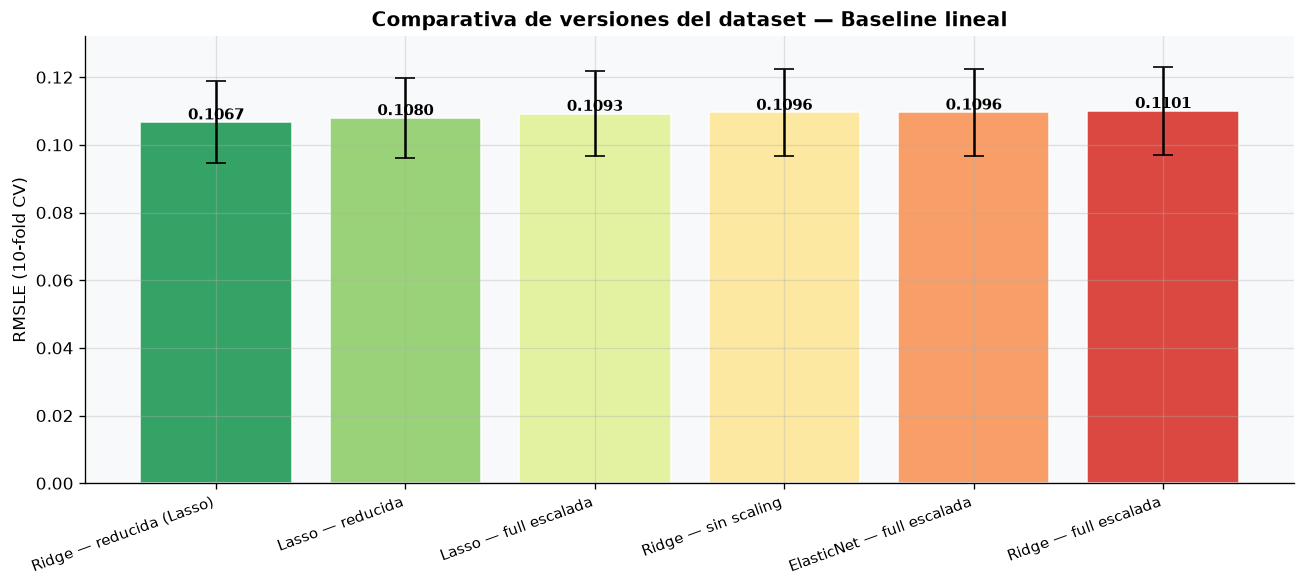


🏆 Mejor configuración: Ridge — reducida (Lasso)
   RMSLE = 0.10674 ± 0.01205


In [14]:
# ─── 6.2 GRÁFICO COMPARATIVO ────────────────────────────────────────────────
results = pd.DataFrame({
    'Configuración': [
        'Ridge — full escalada',
        'Ridge — reducida (Lasso)',
        'Ridge — sin scaling',
        'Lasso — full escalada',
        'Lasso — reducida',
        'ElasticNet — full escalada',
    ],
    'RMSLE_Mean': [s_full.mean(), s_lasso.mean(), s_raw.mean(),
                   s_l_full.mean(), s_l_red.mean(), s_e_full.mean()],
    'RMSLE_Std':  [s_full.std(), s_lasso.std(), s_raw.std(),
                   s_l_full.std(), s_l_red.std(), s_e_full.std()],
}).sort_values('RMSLE_Mean')

print('\n📊 RANKING DE CONFIGURACIONES (menor RMSLE = mejor):')
display(results.reset_index(drop=True).style
        .background_gradient(cmap='RdYlGn_r', subset=['RMSLE_Mean'])
        .format({'RMSLE_Mean': '{:.5f}', 'RMSLE_Std': '{:.5f}'}))

# Gráfico de barras
fig, ax = plt.subplots(figsize=(11, 5))
cmap_bar = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(results)))
bars = ax.bar(range(len(results)), results['RMSLE_Mean'],
              yerr=results['RMSLE_Std'], capsize=6,
              color=cmap_bar, alpha=0.88, edgecolor='white')
ax.set_xticks(range(len(results)))
ax.set_xticklabels(results['Configuración'], rotation=20, ha='right', fontsize=9)
for bar, val in zip(bars, results['RMSLE_Mean']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0008,
            f'{val:.4f}', ha='center', fontsize=9, fontweight='bold')
ax.set_ylabel('RMSLE (10-fold CV)')
ax.set_title('Comparativa de versiones del dataset — Baseline lineal', fontweight='bold')
ax.set_ylim(0, results['RMSLE_Mean'].max() * 1.2)
plt.tight_layout()
plt.savefig('prep_02_cv_comparison.png', bbox_inches='tight', dpi=120)
plt.show()

best_row = results.iloc[0]
print(f'\n🏆 Mejor configuración: {best_row["Configuración"]}')
print(f'   RMSLE = {best_row["RMSLE_Mean"]:.5f} ± {best_row["RMSLE_Std"]:.5f}')

---
## 7 · Análisis de la distribución final del dataset
> Confirmamos que el preprocessing produjo un dataset saludable.

ESTADÍSTICAS DATASET FINAL (versión escalada)
──────────────────────────────────────────────────
  Shape:         (1456, 288)
  Media global:  -0.0353  (esperado ~0 tras RobustScaler)
  Std global:    5.0005   (esperado ~1 tras RobustScaler)
  |Skew| > 1:    200 features
  |Skew| > 0.75: 206 features
  Cols con >50%% ceros: 225 (binarias OHE — normal)


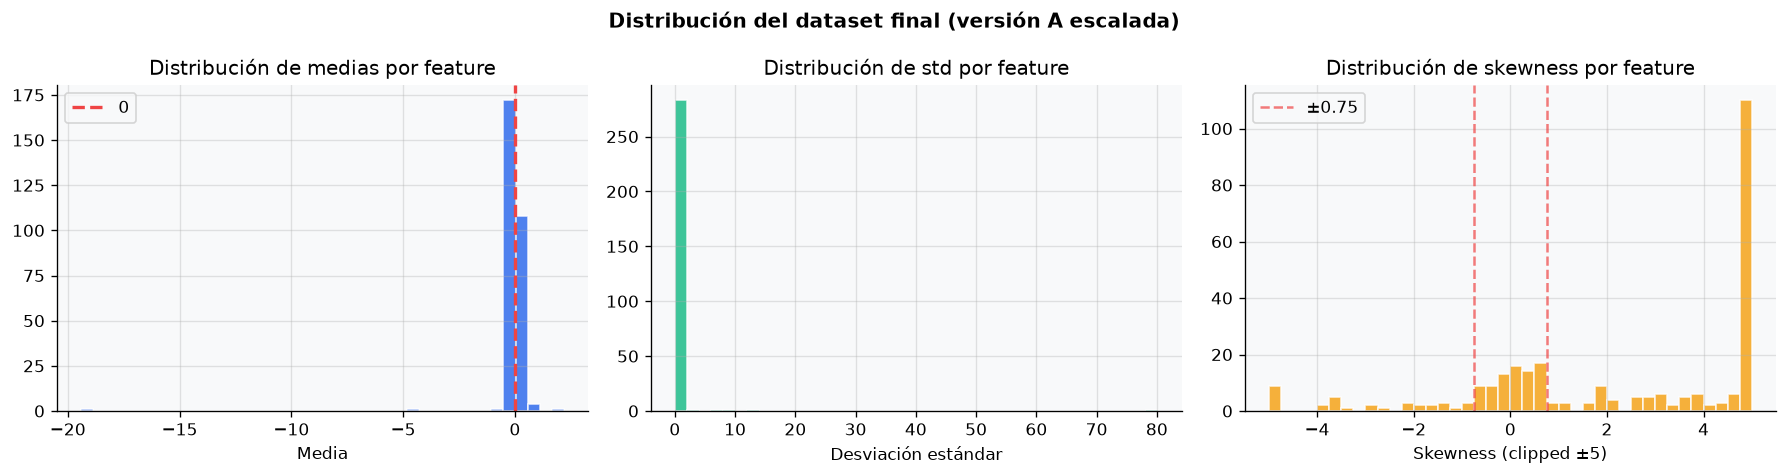

In [15]:
# ─── 7.1 ESTADÍSTICAS DEL DATASET FINAL ────────────────────────────────────
print('ESTADÍSTICAS DATASET FINAL (versión escalada)')
print('─' * 50)
X_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
stats = X_df.describe().T[['mean','std','min','max']]
stats['skew'] = X_df.apply(lambda c: skew(c.dropna())).values
stats['pct_zero'] = (X_df == 0).mean().values * 100

print(f'  Shape:         {X_df.shape}')
print(f'  Media global:  {X_df.values.mean():.4f}  (esperado ~0 tras RobustScaler)')
print(f'  Std global:    {X_df.values.std():.4f}   (esperado ~1 tras RobustScaler)')
print(f'  |Skew| > 1:    {(stats["skew"].abs() > 1).sum()} features')
print(f'  |Skew| > 0.75: {(stats["skew"].abs() > 0.75).sum()} features')
print(f'  Cols con >50%% ceros: {(stats["pct_zero"] > 50).sum()} (binarias OHE — normal)')

# Distribución de medias y std por feature
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Distribución del dataset final (versión A escalada)', fontweight='bold')

ax = axes[0]
ax.hist(stats['mean'], bins=40, color=COLOR_MAIN, alpha=0.8, edgecolor='white')
ax.axvline(0, color=COLOR_DANGER, linestyle='--', linewidth=2, label='0')
ax.set_title('Distribución de medias por feature')
ax.set_xlabel('Media')
ax.legend()

ax = axes[1]
ax.hist(stats['std'], bins=40, color=COLOR_SUCCESS, alpha=0.8, edgecolor='white')
ax.set_title('Distribución de std por feature')
ax.set_xlabel('Desviación estándar')

ax = axes[2]
ax.hist(stats['skew'].clip(-5, 5), bins=40, color=COLOR_ACCENT, alpha=0.8, edgecolor='white')
ax.axvline(-0.75, color=COLOR_DANGER, linestyle='--', alpha=0.7)
ax.axvline( 0.75, color=COLOR_DANGER, linestyle='--', alpha=0.7, label='±0.75')
ax.set_title('Distribución de skewness por feature')
ax.set_xlabel('Skewness (clipped ±5)')
ax.legend()

plt.tight_layout()
plt.savefig('prep_03_dataset_stats.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 8 · Dashboard resumen del pipeline completo

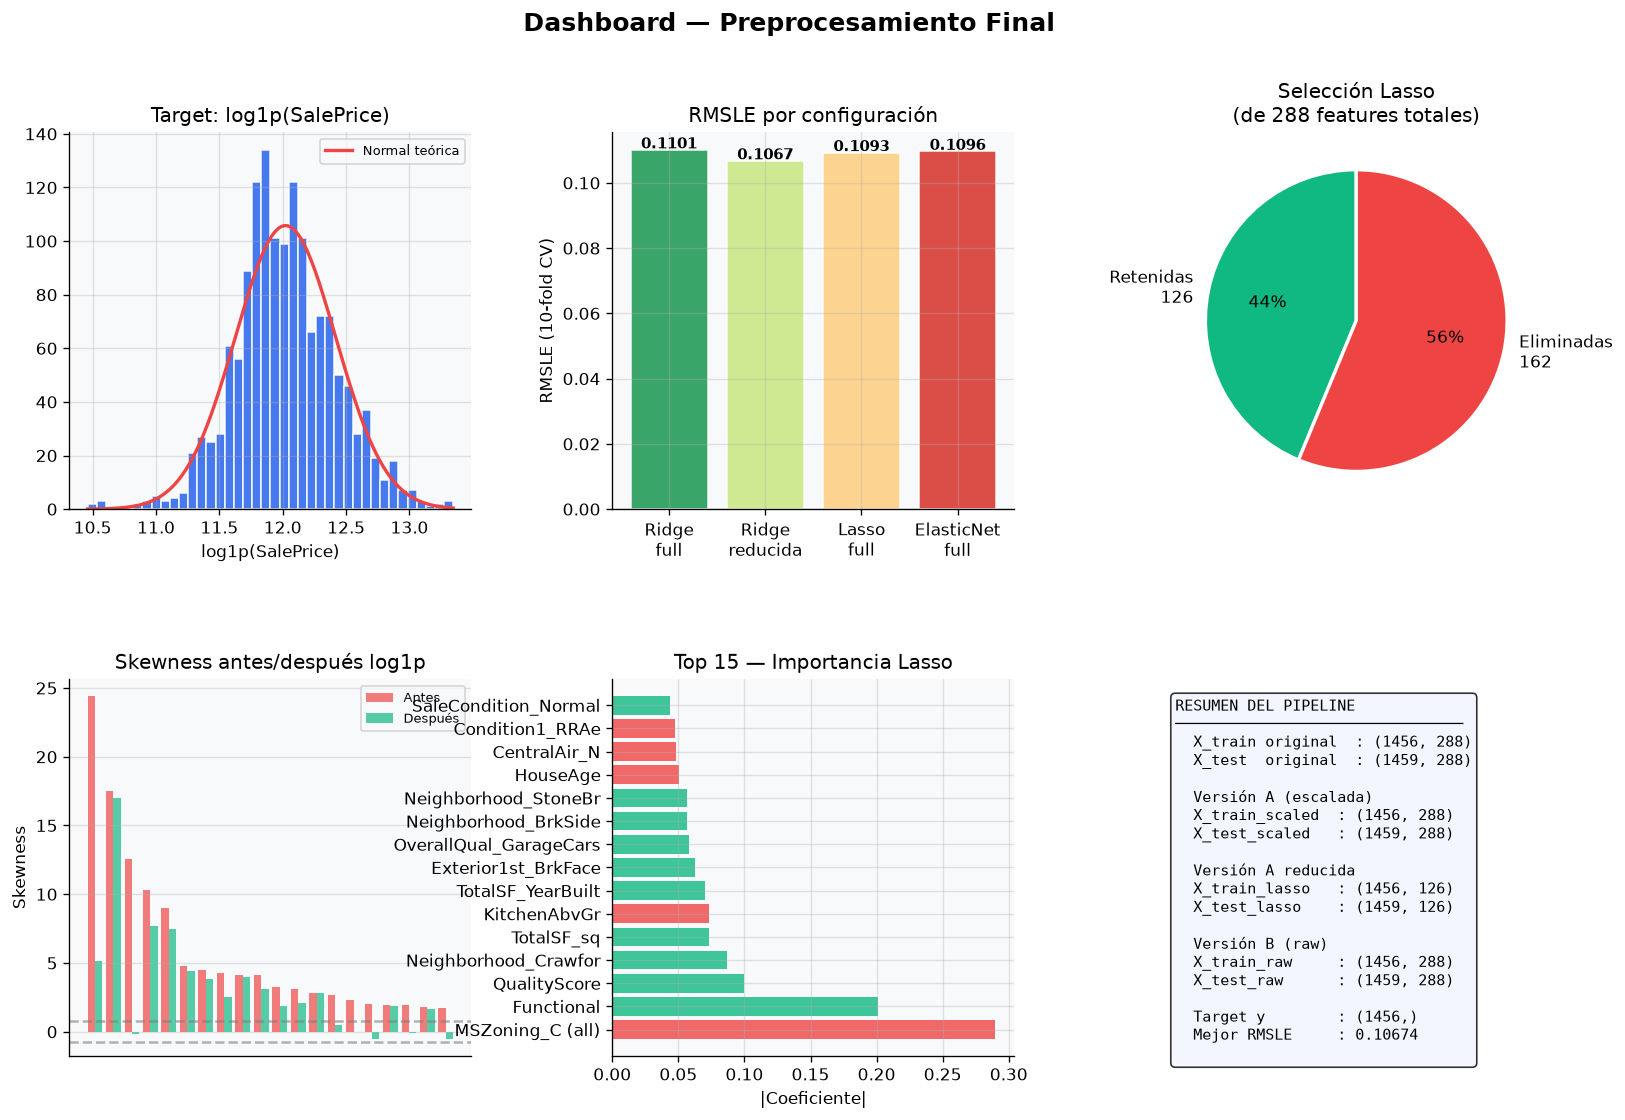

In [16]:
# ─── 8.1 DASHBOARD VISUAL COMPLETO ─────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))
fig.suptitle('Dashboard — Preprocesamiento Final', fontsize=15, fontweight='bold')
gs  = fig.add_gridspec(2, 3, hspace=0.45, wspace=0.35)

# Panel 1: Distribución del target
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(y, bins=40, color=COLOR_MAIN, alpha=0.85, edgecolor='white')
from scipy.stats import norm as _norm
xr = np.linspace(y.min(), y.max(), 200)
ax1.plot(xr, _norm.pdf(xr, y.mean(), y.std()) * len(y) * (y.max()-y.min())/40,
         color=COLOR_DANGER, linewidth=2, label='Normal teórica')
ax1.set_title('Target: log1p(SalePrice)')
ax1.set_xlabel('log1p(SalePrice)')
ax1.legend(fontsize=8)

# Panel 2: Comparativa RMSLE
ax2 = fig.add_subplot(gs[0, 1])
labels_cv = ['Ridge\nfull', 'Ridge\nreducida', 'Lasso\nfull', 'ElasticNet\nfull']
means_cv  = [s_full.mean(), s_lasso.mean(), s_l_full.mean(), s_e_full.mean()]
bar_clr   = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(means_cv)))
bars3 = ax2.bar(labels_cv, means_cv, color=bar_clr, alpha=0.85, edgecolor='white')
for bar, m in zip(bars3, means_cv):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005,
             f'{m:.4f}', ha='center', fontsize=9, fontweight='bold')
ax2.set_ylabel('RMSLE (10-fold CV)')
ax2.set_title('RMSLE por configuración')

# Panel 3: Features seleccionadas vs eliminadas
ax3 = fig.add_subplot(gs[0, 2])
ax3.pie([n_selected, n_eliminated],
        labels=[f'Retenidas\n{n_selected}', f'Eliminadas\n{n_eliminated}'],
        colors=[COLOR_SUCCESS, COLOR_DANGER],
        autopct='%1.0f%%', startangle=90,
        wedgeprops=dict(edgecolor='white', linewidth=2))
ax3.set_title(f'Selección Lasso\n(de {X_train.shape[1]} features totales)')

# Panel 4: Skewness antes y después
ax4 = fig.add_subplot(gs[1, 0])
if len(to_transform) > 0:
    before_vals = [high_skew[c] for c in to_transform[:20]]
    after_vals  = [skew(X_train[c].dropna()) for c in to_transform[:20]]
    x_idx = range(min(20, len(to_transform)))
    ax4.bar([i - 0.2 for i in x_idx], before_vals[:20], 0.4,
            label='Antes', color=COLOR_DANGER, alpha=0.7)
    ax4.bar([i + 0.2 for i in x_idx], after_vals[:20], 0.4,
            label='Después', color=COLOR_SUCCESS, alpha=0.7)
    ax4.axhline(0.75,  color='gray', linestyle='--', alpha=0.6)
    ax4.axhline(-0.75, color='gray', linestyle='--', alpha=0.6)
    ax4.set_title('Skewness antes/después log1p')
    ax4.set_ylabel('Skewness')
    ax4.legend(fontsize=8)
    ax4.set_xticks([])
else:
    ax4.text(0.5, 0.5, 'No se aplicaron\ntransformaciones\nadicionales',
             ha='center', va='center', transform=ax4.transAxes)
    ax4.set_title('Skewness — sin cambios adicionales')

# Panel 5: Coeficientes Lasso top 15
ax5 = fig.add_subplot(gs[1, 1])
top15 = coef_df.head(15)
clrs = [COLOR_SUCCESS if c > 0 else COLOR_DANGER for c in top15['Coef']]
ax5.barh(top15['Feature'], top15['Coef_Abs'], color=clrs, alpha=0.8)
ax5.set_title('Top 15 — Importancia Lasso')
ax5.set_xlabel('|Coeficiente|')

# Panel 6: Resumen de shapes
ax6 = fig.add_subplot(gs[1, 2])
ax6.axis('off')
summary_text = (
    f"RESUMEN DEL PIPELINE\n"
    f"{'─'*32}\n"
    f"  X_train original  : {X_train.shape}\n"
    f"  X_test  original  : {X_test.shape}\n\n"
    f"  Versión A (escalada)\n"
    f"  X_train_scaled  : {X_train_scaled.shape}\n"
    f"  X_test_scaled   : {X_test_scaled.shape}\n\n"
    f"  Versión A reducida\n"
    f"  X_train_lasso   : {X_train_lasso.shape}\n"
    f"  X_test_lasso    : {X_test_lasso.shape}\n\n"
    f"  Versión B (raw)\n"
    f"  X_train_raw     : {X_train_raw.shape}\n"
    f"  X_test_raw      : {X_test_raw.shape}\n\n"
    f"  Target y        : {y.shape}\n"
    f"  Mejor RMSLE     : {results['RMSLE_Mean'].min():.5f}\n"
)
ax6.text(0.05, 0.95, summary_text,
         transform=ax6.transAxes, fontsize=9,
         verticalalignment='top', fontfamily='monospace',
         bbox=dict(boxstyle='round', facecolor='#f0f4ff', alpha=0.8))

plt.savefig('prep_04_dashboard.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 9 · Guardado de artefactos finales
> Todo lo que necesita el notebook de modelado.

In [17]:
# ─── 9.1 GUARDAR TODOS LOS ARTEFACTOS ──────────────────────────────────────

# ── Arrays numpy ────────────────────────────────────────────────────────────
np.save('X_train_scaled.npy',  X_train_scaled)   # Versión A — full escalada
np.save('X_test_scaled.npy',   X_test_scaled)
np.save('X_train_lasso.npy',   X_train_lasso)    # Versión A — reducida
np.save('X_test_lasso.npy',    X_test_lasso)
np.save('X_train_raw.npy',     X_train_raw)      # Versión B — sin scaling
np.save('X_test_raw.npy',      X_test_raw)
np.save('y_train_log.npy',     y.values)

# ── Scalers y máscaras ──────────────────────────────────────────────────────
joblib.dump(scaler_robust, 'scaler_robust.pkl')
joblib.dump(coef_mask,     'lasso_feature_mask.pkl')

# ── Feature names ───────────────────────────────────────────────────────────
with open('feature_names_full.txt', 'w') as f:
    f.write('\n'.join(X_train.columns.tolist()))

with open('feature_names_lasso.txt', 'w') as f:
    f.write('\n'.join(feature_names_lasso))

# ── IDs del test para submission ────────────────────────────────────────────
test_ids.to_csv('test_ids.csv', index=False)

# ── Resumen de CV para referencia ───────────────────────────────────────────
cv_results = results.copy()
cv_results.to_csv('baseline_cv_results.csv', index=False)

print('✅ Artefactos guardados:')
artefacts = {
    'X_train_scaled.npy'   : 'Versión A — full escalada (modelos lineales)',
    'X_test_scaled.npy'    : 'Versión A — full escalada (modelos lineales)',
    'X_train_lasso.npy'    : 'Versión A — reducida por Lasso',
    'X_test_lasso.npy'     : 'Versión A — reducida por Lasso',
    'X_train_raw.npy'      : 'Versión B — sin scaling (tree-based)',
    'X_test_raw.npy'       : 'Versión B — sin scaling (tree-based)',
    'y_train_log.npy'      : 'Target en log-space',
    'scaler_robust.pkl'    : 'RobustScaler fiteado en train',
    'lasso_feature_mask.pkl': 'Máscara booleana selección Lasso',
    'feature_names_full.txt': 'Nombres de features — versión completa',
    'feature_names_lasso.txt': 'Nombres de features — versión reducida',
    'test_ids.csv'         : 'IDs para submission',
    'baseline_cv_results.csv': 'Resultados CV baseline',
}
for fname, desc in artefacts.items():
    if os.path.exists(fname):
        size = os.path.getsize(fname) / 1024
        print(f'   📄 {fname:<28} {size:6.1f} KB  — {desc}')
    else:
        print(f'   ⚠️  {fname} NO encontrado')

✅ Artefactos guardados:
   📄 X_train_scaled.npy           3276.1 KB  — Versión A — full escalada (modelos lineales)
   📄 X_test_scaled.npy            3282.9 KB  — Versión A — full escalada (modelos lineales)
   📄 X_train_lasso.npy            1433.4 KB  — Versión A — reducida por Lasso
   📄 X_test_lasso.npy             1436.3 KB  — Versión A — reducida por Lasso
   📄 X_train_raw.npy              1638.1 KB  — Versión B — sin scaling (tree-based)
   📄 X_test_raw.npy               1641.5 KB  — Versión B — sin scaling (tree-based)
   📄 y_train_log.npy                11.5 KB  — Target en log-space
   📄 scaler_robust.pkl              10.1 KB  — RobustScaler fiteado en train
   📄 lasso_feature_mask.pkl          0.5 KB  — Máscara booleana selección Lasso
   📄 feature_names_full.txt          4.6 KB  — Nombres de features — versión completa
   📄 feature_names_lasso.txt         2.0 KB  — Nombres de features — versión reducida
   📄 test_ids.csv                    8.6 KB  — IDs para submission
   📄 

In [18]:
# ─── 9.2 RESUMEN EJECUTIVO ──────────────────────────────────────────────────
print('=' * 68)
print('  RESUMEN EJECUTIVO — PREPROCESAMIENTO FINAL')
print('=' * 68)
print(f'''
📥 INPUT (desde Feature Engineering)
   X_train_FE.parquet  : {X_train.shape}
   X_test_FE.parquet   : {X_test.shape}
   y_train.npy         : {y.shape}  (log1p-space)

🔧 PASOS APLICADOS
   1. Validación de integridad    → 0 nulos, 0 infinitos
   2. Corrección de dtypes        → todas numéricas
   3. log1p en features sesgadas  → {len(to_transform)} features transformadas
   4. Versión A (RobustScaler)    → {X_train_scaled.shape}
   5. Versión B (sin scaling)     → {X_train_raw.shape}
   6. Selección Lasso             → {n_selected}/{X_train.shape[1]} features retenidas

📊 BASELINE 10-FOLD CV (Ridge α=10)
   Versión A completa : RMSLE = {s_full.mean():.5f} ± {s_full.std():.5f}
   Versión A reducida : RMSLE = {s_lasso.mean():.5f} ± {s_lasso.std():.5f}
   Lasso full         : RMSLE = {s_l_full.mean():.5f} ± {s_l_full.std():.5f}
   ElasticNet full    : RMSLE = {s_e_full.mean():.5f} ± {s_e_full.std():.5f}

📤 ARTEFACTOS PARA EL NOTEBOOK DE MODELADO
   X_train_scaled.npy  → Ridge / Lasso / ElasticNet / SVR
   X_train_lasso.npy   → alternativa reducida para lineales
   X_train_raw.npy     → XGBoost / LightGBM / RandomForest
   y_train_log.npy     → target (al predecir: np.expm1())
   scaler_robust.pkl   → para transformar nuevos datos en producción

🚀 SIGUIENTE PASO — Notebook 4: Modelado Avanzado
   - XGBoost + Optuna (tune: max_depth, learning_rate, n_estimators, ...)
   - LightGBM + Optuna
   - Stacking / Blending de modelos
   - Objetivo: RMSLE < 0.115 en CV → < 0.12 en Kaggle public LB
''')
print('=' * 68)

  RESUMEN EJECUTIVO — PREPROCESAMIENTO FINAL

📥 INPUT (desde Feature Engineering)
   X_train_FE.parquet  : (1456, 288)
   X_test_FE.parquet   : (1459, 288)
   y_train.npy         : (1456,)  (log1p-space)

🔧 PASOS APLICADOS
   1. Validación de integridad    → 0 nulos, 0 infinitos
   2. Corrección de dtypes        → todas numéricas
   3. log1p en features sesgadas  → 49 features transformadas
   4. Versión A (RobustScaler)    → (1456, 288)
   5. Versión B (sin scaling)     → (1456, 288)
   6. Selección Lasso             → 126/288 features retenidas

📊 BASELINE 10-FOLD CV (Ridge α=10)
   Versión A completa : RMSLE = 0.11010 ± 0.01300
   Versión A reducida : RMSLE = 0.10674 ± 0.01205
   Lasso full         : RMSLE = 0.10926 ± 0.01259
   ElasticNet full    : RMSLE = 0.10964 ± 0.01286

📤 ARTEFACTOS PARA EL NOTEBOOK DE MODELADO
   X_train_scaled.npy  → Ridge / Lasso / ElasticNet / SVR
   X_train_lasso.npy   → alternativa reducida para lineales
   X_train_raw.npy     → XGBoost / LightGBM / Rand